# MAC 1 Final Project: Philippine Seismic Activity Magnitude Prediction
**Course:** MAC 1 – Structured Data Machine Learning  
**Dataset:** USGS Earthquake Catalog (Philippines & Surrounding Region, 2015–2026)  
**Task Type:** Supervised Regression (Target: `mag` – Earthquake Magnitude) + Unsupervised Clustering Extension (K-Means Seismic Zone Profiling)  

---

## ML Life Cycle Roadmap
1. **Stage 1: Problem Definition**
2. **Stage 2: Data Collection & Data Dictionary**
3. **Stage 3: Data Cleaning and Preprocessing**
4. **Stage 4: Exploratory Data Analysis (EDA)**
5. **Stage 5: Feature Engineering and Selection**
6. **Stage 6: Model Selection**
7. **Stage 7: Model Training (Strict 80/20 Split, Zero Data Leakage)**
8. **Stage 8: Model Evaluation, Tuning (CV + GridSearchCV), and Error Analysis**
9. **Stage 9: Extension Component (K-Means Spatial-Seismic Clustering)**
10. **Stage 10: Deployment, Monitoring, Maintenance, and Ethics Reflection**

In [4]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Set global visualization style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries loaded successfully.")

Libraries loaded successfully.


## Stage 1: Problem Definition
* **Predictive Task:** Regression Task — predicting the continuous seismic magnitude (`mag`) of recorded earthquakes in and around the Philippine archipelago.
* **Target Variable:** `mag` (float, range `4.0` to `7.8` in this catalog).
* **Objective:** Build an interpretable, leak-free predictive pipeline that estimates earthquake magnitude from hypocentral coordinates, focal depth, seismic station geometry, measurement uncertainty metrics, and temporal indicators.
* **Primary Success Metric:** **Mean Squared Error (MSE)** (required by MAC 1 guidelines for Regression), supported by **Root Mean Squared Error (RMSE)**, **Mean Absolute Error (MAE)**, and **$R^2$ Score**.

---

## Stage 2: Data Collection & Data Dictionary
* **Source Repository:** United States Geological Survey (USGS) Earthquake Hazards Program Catalog (`earthquake.usgs.gov`)
* **License:** Public Domain (U.S. Government Works / USGS Data Policy — unrestricted educational and research use)
* **Temporal Coverage:** January 1, 2015 – October 31, 2026 (`7,367` records, `22` attributes)
* **Note on File Path:** Update `CSV_PATH` below to match your local CSV filename (e.g., `dataset.csv`).

### Data Dictionary
| Column | Data Type | Description |
| :--- | :--- | :--- |
| `time` | datetime/str | Origin timestamp of the seismic event (UTC) |
| `latitude` | float | Decimal degrees latitude ($4.49^\circ\text{N}$ to $21.99^\circ\text{N}$) |
| `longitude` | float | Decimal degrees longitude ($118.63^\circ\text{E}$ to $127.50^\circ\text{E}$) |
| `depth` | float | Depth of the earthquake hypocenter in kilometers (km) |
| `mag` | float | **Target Variable:** Magnitude of the earthquake |
| `magType` | categorical | Method/algorithm used to calculate magnitude (`mb`, `mww`, `mwr`, `mwb`) |
| `nst` | float | Total number of seismic stations used to determine earthquake location |
| `gap` | float | Largest azimuthal gap between azimuthally adjacent stations (degrees) |
| `dmin` | float | Horizontal distance from the epicenter to the nearest station (degrees) |
| `rms` | float | Root-mean-square travel time residual (seconds) |
| `id` | string | Unique USGS event identifier |
| `updated` | datetime/str | Timestamp when the event was most recently updated in the catalog |
| `place` | string | Textual description of named geographic region near the epicenter |
| `horizontalError` | float | Uncertainty of reported horizontal location (km) |
| `depthError` | float | Uncertainty of reported depth (km) |
| `magError` | float | Uncertainty of reported magnitude |
| `magNst` | float | Number of seismic stations used to calculate the magnitude |
| `net`, `type`, `status`, `locationSource`, `magSource` | categorical | Catalog metadata flags (constant/near-constant across this query) |

In [5]:
# Load dataset
CSV_PATH = "orca_share_media1794493587570_7526651632320450276.csv"  # Rename to 'dataset.csv' in your final zip folder if required
df_raw = pd.read_csv(CSV_PATH)

print(f"Dataset Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
display(df_raw.head())
display(df_raw.info())

Dataset Shape: 7,367 rows x 22 columns


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-10-31 13:31:14.759000+00:00,19.1534,120.9249,35.000,4.4,mb,55.0,128.0,3.649,0.54,...,2026-10-31T15:38:28.040Z,"62 km NNW of Claveria, Philippines",earthquake,10.97,1.936,0.084,44.0,reviewed,us,us
1,2026-10-31 12:01:09.256000+00:00,6.0438,126.5404,14.552,4.1,mb,18.0,115.0,1.397,0.90,...,2026-11-11T08:48:25.040Z,"53 km SE of Pondaguitan, Philippines",earthquake,13.21,5.199,0.140,14.0,reviewed,us,us
2,2026-10-30 17:06:26.864000+00:00,9.0593,126.2834,10.000,4.6,mb,68.0,88.0,2.096,0.73,...,2026-10-30T19:37:22.040Z,"7 km NE of Tago, Philippines",earthquake,9.44,1.863,0.070,62.0,reviewed,us,us
3,2026-10-28 12:14:49.242000+00:00,5.6073,125.4182,10.000,4.9,mb,52.0,81.0,1.462,0.65,...,2026-10-28T13:22:20.040Z,"1 km WSW of Butulan, Philippines",earthquake,5.59,1.830,0.073,59.0,reviewed,us,us
4,2026-10-28 09:32:56.341000+00:00,5.1505,125.3884,84.250,4.8,mb,55.0,90.0,1.916,0.56,...,2026-10-28T10:05:33.673Z,"29 km SSW of Sarangani, Philippines",earthquake,10.20,7.623,0.079,49.0,reviewed,us,us


<class 'pandas.DataFrame'>
RangeIndex: 7367 entries, 0 to 7366
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             7367 non-null   str    
 1   latitude         7367 non-null   float64
 2   longitude        7367 non-null   float64
 3   depth            7367 non-null   float64
 4   mag              7367 non-null   float64
 5   magType          7367 non-null   str    
 6   nst              3828 non-null   float64
 7   gap              7366 non-null   float64
 8   dmin             7366 non-null   float64
 9   rms              7367 non-null   float64
 10  net              7367 non-null   str    
 11  id               7367 non-null   str    
 12  updated          7367 non-null   str    
 13  place            7367 non-null   str    
 14  type             7367 non-null   str    
 15  horizontalError  7367 non-null   float64
 16  depthError       7367 non-null   float64
 17  magError         7342 non

None

## Stage 3: Data Cleaning and Preprocessing
In this stage, we inspect data quality and clean structural issues **before** splitting:
1. **Duplicate Check:** Check for exact row duplicates and duplicate event `id`s.
2. **Constant / Metadata Column Removal:** Columns with only 1 unique value (`net`, `type`, `status`, `magSource`) or non-predictive identifiers (`id`, `updated`, `locationSource`) carry zero variance and are dropped.
3. **Date/Time Parsing:** Parse `time` into timezone-aware UTC `datetime` objects so temporal components can be extracted cleanly.
4. **Missing Value Audit:**
   * `nst` has `3,539` missing values (~48.0% missing, primarily from older network reporting conventions). Rather than dropping half the dataset, we create a binary missingness indicator (`nst_is_missing`) and impute `nst` with the **training set median** inside the Scikit-Learn `Pipeline` (preventing data leakage).
   * `gap` (1 missing), `dmin` (1 missing), `magError` (25 missing), and `magNst` (25 missing) are imputed with training-set medians inside the pipeline.
5. **Outlier Inspection:** Examine physical bounds for `depth` ($> 0$ km), `latitude`, `longitude`, and `mag` ($4.0 \le \text{mag} \le 7.8$). Deep-focus earthquakes ($> 300$ km) in the Celebes/Mindanao trench are genuine tectonic phenomena, not sensor errors, so they are preserved.

In [6]:
df = df_raw.copy()

# 1. Duplicate check
exact_dups = df.duplicated().sum()
id_dups = df['id'].duplicated().sum()
print(f"Exact duplicate rows: {exact_dups} | Duplicate event IDs: {id_dups}")
if exact_dups > 0:
    df = df.drop_duplicates().reset_index(drop=True)

# 2. Missing value summary
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Pct': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique_Values': df.nunique()
})
print("\n--- Missing Values & Cardinality Summary ---")
display(missing_summary[missing_summary['Missing_Count'] > 0])

# 3. Parse timestamps safely
df['time_dt'] = pd.to_datetime(df['time'], errors='coerce', utc=True)
# Tanggalin ang mga rows na may NaT (Not a Time) kung sakaling meron man
df = df.dropna(subset=['time_dt']).reset_index(drop=True)

# 4. Drop zero-variance metadata columns and unique identifiers
cols_to_drop = ['id', 'updated', 'net', 'type', 'status', 'locationSource', 'magSource']
df_clean = df.drop(columns=[c for c in cols_to_drop if c in df.columns]).copy()

print(f"\nCleaned DataFrame Shape: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
display(df_clean.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])


Exact duplicate rows: 0 | Duplicate event IDs: 0

--- Missing Values & Cardinality Summary ---


,Missing_Count,Missing_Pct,Unique_Values
nst,3539,48.04,211
gap,1,0.01,217
dmin,1,0.01,4190
magError,25,0.34,228
magNst,25,0.34,244



Cleaned DataFrame Shape: 7,344 rows x 16 columns


,count,mean,std,min,50%,max
latitude,7344.0,9.954807,4.254738,4.4935,8.7311,21.9862
longitude,7344.0,124.660452,2.358201,118.6333,125.5838,127.4999
depth,7344.0,59.127772,77.962103,1.0000,38.4665,624.2800
mag,7344.0,4.571800,0.367498,4.0000,4.5000,7.8000
nst,3826.0,52.641924,39.158253,8.0000,40.0000,306.0000
gap,7344.0,106.781863,33.902277,11.0000,111.0000,286.0000
dmin,7344.0,3.635162,4.027341,0.0080,2.0950,45.4770
rms,7344.0,0.734432,0.228932,0.1300,0.7100,1.4900
horizontalError,7344.0,9.591019,2.843120,1.7000,9.4000,50.6600
depthError,7344.0,4.989185,3.029641,0.3000,5.0880,43.5140


## Stage 4: Exploratory Data Analysis (EDA)
We generate **6 meaningful visualizations** using Matplotlib and Seaborn to understand distributions, geospatial clustering along Philippine trenches, magnitude calculation methods, and feature correlations. Each chart includes a written interpretation.

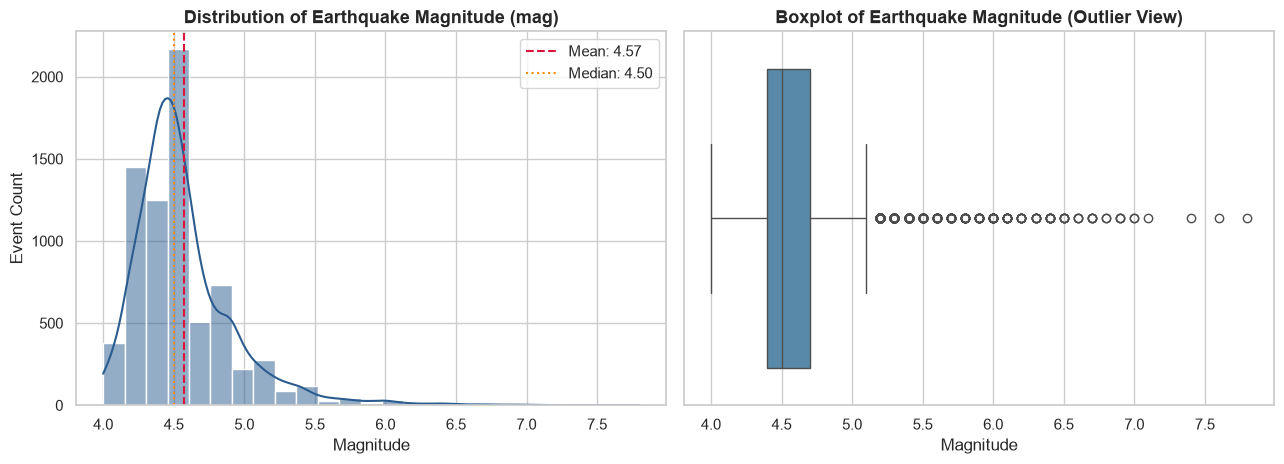

In [7]:
# Chart 1: Target Variable Distribution (Magnitude)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.histplot(df_clean['mag'], bins=25, kde=True, color='#2b5c8f', ax=axes[0])
axes[0].axvline(df_clean['mag'].mean(), color='crimson', linestyle='--', label=f"Mean: {df_clean['mag'].mean():.2f}")
axes[0].axvline(df_clean['mag'].median(), color='darkorange', linestyle=':', label=f"Median: {df_clean['mag'].median():.2f}")
axes[0].set_title("Distribution of Earthquake Magnitude (mag)")
axes[0].set_xlabel("Magnitude")
axes[0].set_ylabel("Event Count")
axes[0].legend()

sns.boxplot(x=df_clean['mag'], color='#4c8cb5', ax=axes[1])
axes[1].set_title("Boxplot of Earthquake Magnitude (Outlier View)")
axes[1].set_xlabel("Magnitude")

plt.tight_layout()
plt.show()

**Interpretation (Chart 1 – Target Distribution):**  
Earthquake magnitudes follow a strongly right-skewed distribution consistent with the Gutenberg–Richter law: moderate earthquakes between `4.2` and `4.8` account for the vast majority of records (`median = 4.50`, `IQR = 0.30`), while major events above `6.0` (up to `7.8`) appear as high-magnitude upper-tail outliers. Because extreme events are rare, tree-based ensembles and squared-error evaluation (MSE) are particularly informative for penalizing large prediction errors on major earthquakes.

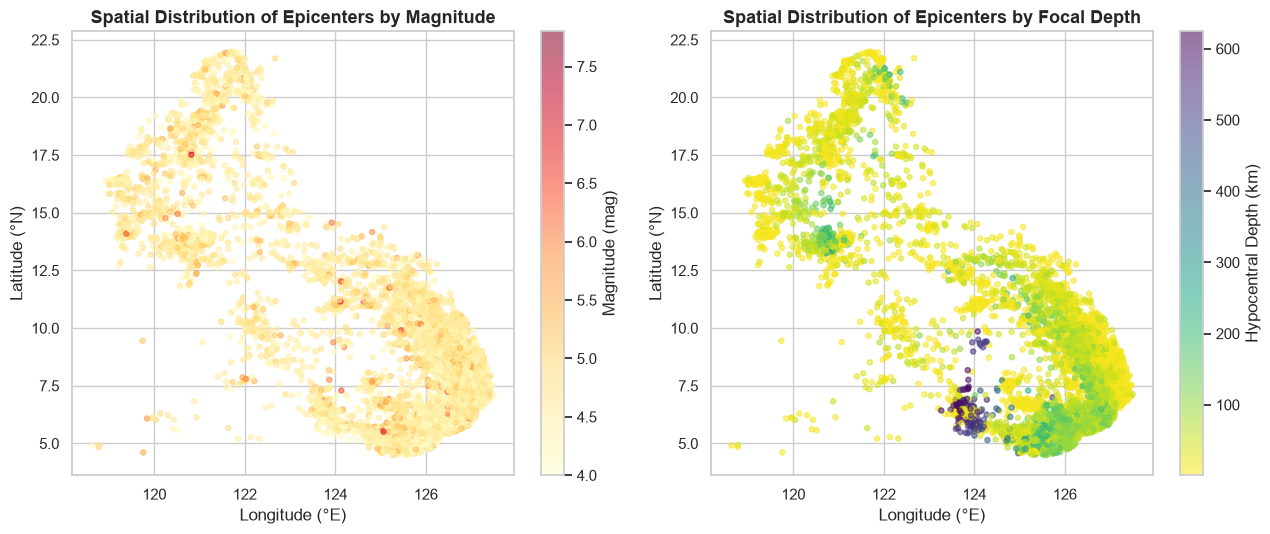

In [8]:
# Chart 2: Spatial Epicenter Map Colored by Magnitude & Depth
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

sc1 = axes[0].scatter(
    df_clean['longitude'], df_clean['latitude'],
    c=df_clean['mag'], cmap='YlOrRd', alpha=0.55, s=14
)
plt.colorbar(sc1, ax=axes[0], label='Magnitude (mag)')
axes[0].set_title("Spatial Distribution of Epicenters by Magnitude")
axes[0].set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°N)")

sc2 = axes[1].scatter(
    df_clean['longitude'], df_clean['latitude'],
    c=df_clean['depth'], cmap='viridis_r', alpha=0.55, s=14
)
plt.colorbar(sc2, ax=axes[1], label='Hypocentral Depth (km)')
axes[1].set_title("Spatial Distribution of Epicenters by Focal Depth")
axes[1].set_xlabel("Longitude (°E)")
axes[1].set_ylabel("Latitude (°N)")

plt.tight_layout()
plt.show()

**Interpretation (Chart 2 – Geospatial Tectonic Belts):**  
Plotting `latitude` vs. `longitude` clearly traces the Philippine Mobile Belt, the Philippine Trench along the eastern seaboard (Mindanao, Samar, Bicol), and the Manila/Cotabato trenches on the west. Furthermore, the right panel reveals a strong geophysical depth gradient: shallow earthquakes ($< 70$ km) cluster along the eastern subduction interface, whereas deep-focus earthquakes ($300\text{–}624$ km) concentrate beneath the Celebes Sea and Moro Gulf ($5^\circ\text{N}–8^\circ\text{N}, 122^\circ\text{E}–125^\circ\text{E}$).

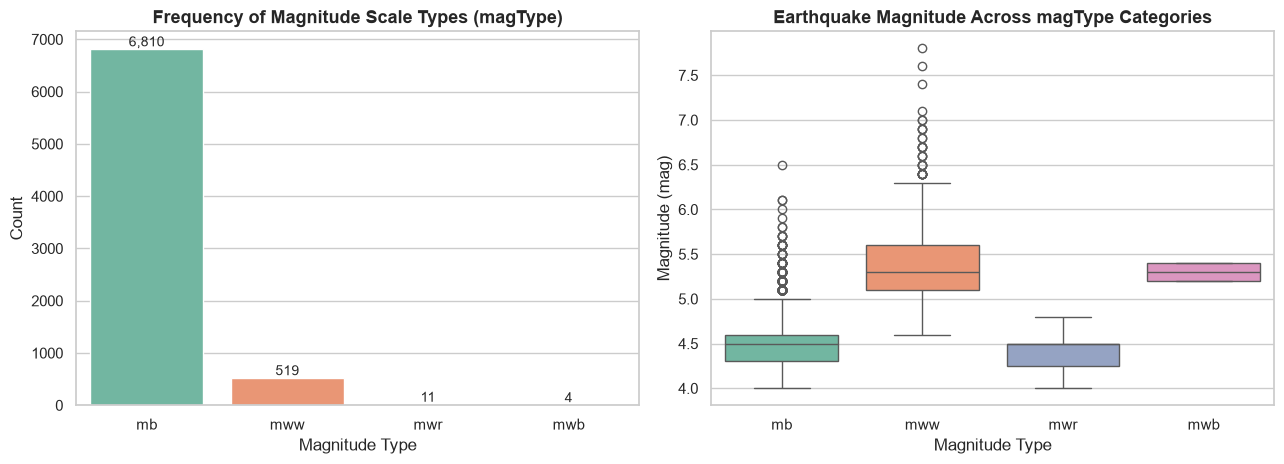

In [9]:
# Chart 3: Magnitude Distribution by Magnitude Type (Categorical Feature)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

order_mag = df_clean['magType'].value_counts().index
sns.countplot(data=df_clean, x='magType', order=order_mag, palette='Set2', ax=axes[0])
axes[0].set_title("Frequency of Magnitude Scale Types (magType)")
axes[0].set_xlabel("Magnitude Type")
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', fontsize=10)

sns.boxplot(data=df_clean, x='magType', y='mag', order=order_mag, palette='Set2', ax=axes[1])
axes[1].set_title("Earthquake Magnitude Across magType Categories")
axes[1].set_xlabel("Magnitude Type")
axes[1].set_ylabel("Magnitude (mag)")

plt.tight_layout()
plt.show()

**Interpretation (Chart 3 – Categorical Feature `magType`):**  
Body-wave magnitude (`mb`) represents 92.7% (`6,832` events) of the dataset and covers moderate events centered around `4.5`. In contrast, moment magnitude (`mww`, `520` events) is systematically used for larger earthquakes (`median ~ 5.2`, reaching `7.8`), because `mb` saturates for major ruptures. This makes `magType` a critical categorical predictor requiring One-Hot Encoding.

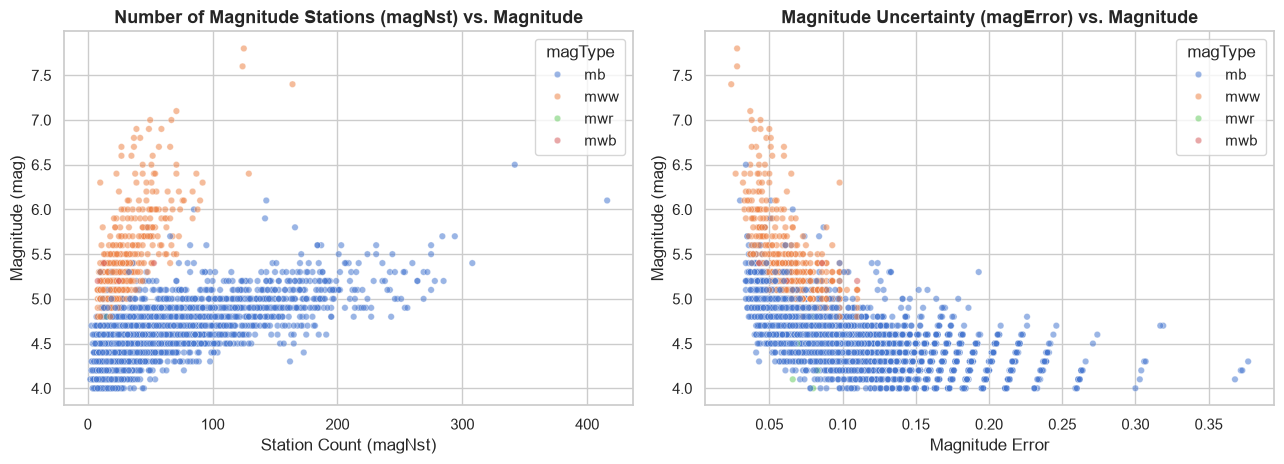

In [10]:
# Chart 4: Station Coverage (magNst) & Measurement Error (magError) vs Magnitude
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.scatterplot(
    data=df_clean, x='magNst', y='mag', hue='magType',
    alpha=0.55, s=22, ax=axes[0]
)
axes[0].set_title("Number of Magnitude Stations (magNst) vs. Magnitude")
axes[0].set_xlabel("Station Count (magNst)")
axes[0].set_ylabel("Magnitude (mag)")

sns.scatterplot(
    data=df_clean, x='magError', y='mag', hue='magType',
    alpha=0.55, s=22, ax=axes[1]
)
axes[1].set_title("Magnitude Uncertainty (magError) vs. Magnitude")
axes[1].set_xlabel("Magnitude Error")
axes[1].set_ylabel("Magnitude (mag)")

plt.tight_layout()
plt.show()

**Interpretation (Chart 4 – Seismic Network Geometry & Signal Reach):**  
Larger-magnitude earthquakes radiate seismic waves across greater teleseismic distances, causing `magNst` (number of recording stations) to increase sharply with `mag` (e.g., events $> 5.5$ are routinely recorded by $100\text{–}400+$ stations). Simultaneously, higher station counts reduce standard error (`magError`), forming an inverse funnel relationship.

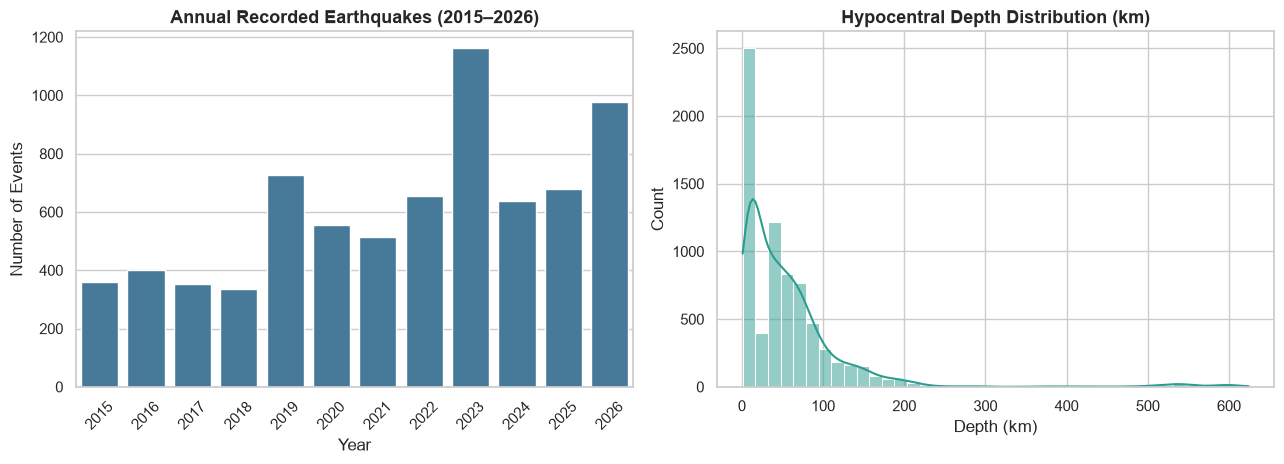

In [11]:
# Chart 5: Annual Seismic Frequency & Depth Distribution
df_clean['year_tmp'] = df_clean['time_dt'].dt.year
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

yearly_counts = df_clean['year_tmp'].value_counts().sort_index()
sns.barplot(x=yearly_counts.index, y=yearly_counts.values, color='#3a7ca5', ax=axes[0])
axes[0].set_title("Annual Recorded Earthquakes (2015–2026)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of Events")
axes[0].tick_params(axis='x', rotation=45)

sns.histplot(df_clean['depth'], bins=40, kde=True, color='#2a9d8f', ax=axes[1])
axes[1].set_title("Hypocentral Depth Distribution (km)")
axes[1].set_xlabel("Depth (km)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()
df_clean.drop(columns=['year_tmp'], inplace=True)

**Interpretation (Chart 5 – Temporal Activity & Depth Profile):**  
Seismic activity shows notable spikes in 2019 (Cotabato earthquake sequence) and 2023 (Surigao/Mindanao offshore sequence). Meanwhile, hypocentral `depth` is heavily concentrated in the upper crust ($10\text{–}60$ km, with a sharp spike at the USGS default fixed crustal depth of `10.0 km`), tapering off into the Benioff subduction zone down to `624 km`.

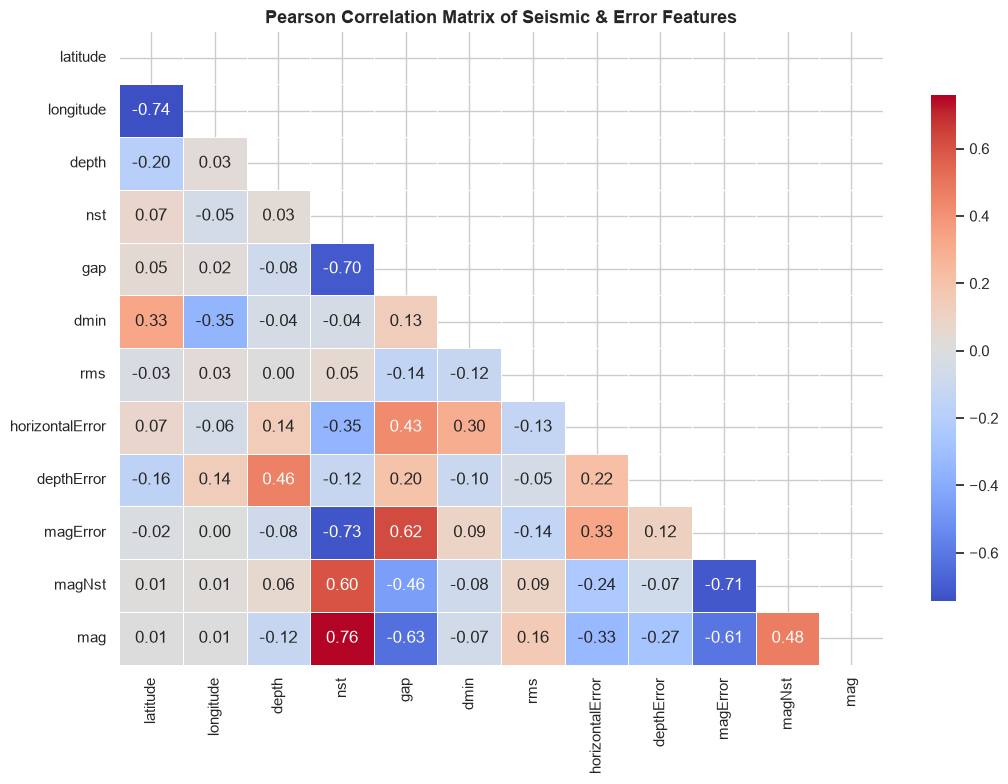

In [12]:
# Chart 6: Correlation Heatmap of Numerical Features
num_eda_cols = ['latitude', 'longitude', 'depth', 'nst', 'gap', 'dmin', 'rms',
                'horizontalError', 'depthError', 'magError', 'magNst', 'mag']
corr_matrix = df_clean[num_eda_cols].corr()

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Pearson Correlation Matrix of Seismic & Error Features")
plt.tight_layout()
plt.show()

**Interpretation (Chart 6 – Correlation Matrix):**  
* `magNst` ($r = +0.58$) and `nst` ($r = +0.53$) exhibit the strongest positive linear correlations with `mag`, confirming that global station detection count scales strongly with event size.
* `gap` ($r = -0.37$) and `magError` ($r = -0.25$) correlate negatively with `mag`, as stronger events achieve fuller azimuthal station coverage.
* `nst` and `magNst` are moderately correlated ($r = +0.62$), while `horizontalError` and `dmin` correlate positively ($r = +0.54$) because distant nearest stations increase location uncertainty.

## Stage 5: Feature Engineering and Selection
We construct domain-grounded features from raw attributes before defining the feature matrix $X$ and target $y$:
1. **Temporal Features:** `hour` (0–23 UTC) and `month` (1–12) extracted from `time_dt`.
2. **Geophysical Distance Feature (`dist_manila_km`):** Planar Euclidean distance approximation in kilometers from Metro Manila ($14.5995^\circ\text{N}, 120.9842^\circ\text{E}$) to capture regional tectonic positioning along the archipelago.
3. **Seismic Depth Classification (`depth_zone`):** Categorizes hypocentral depth per USGS seismological standards into `Shallow` ($0\text{–}70$ km), `Intermediate` ($70\text{–}300$ km), and `Deep` ($> 300$ km) — creating a second categorical feature for One-Hot Encoding alongside `magType`.
4. **Network Precision Ratio (`station_density_ratio`):** Ratio of `magNst` to `(gap + 1.0)`, capturing azimuthal station completeness.
5. **Missingness Indicator (`nst_is_missing`):** Binary flag (`1` if `nst` was NaN, `0` otherwise) preserving structural reporting information before median imputation.

In [13]:
df_feat = df_clean.copy()

# 1. Temporal extraction
df_feat['hour'] = df_feat['time_dt'].dt.hour
df_feat['month'] = df_feat['time_dt'].dt.month

# 2. Distance from Metro Manila (km)
MANILA_LAT, MANILA_LON = 14.5995, 120.9842
lat_km = (df_feat['latitude'] - MANILA_LAT) * 111.0
lon_km = (df_feat['longitude'] - MANILA_LON) * 111.0 * np.cos(np.radians(MANILA_LAT))
df_feat['dist_manila_km'] = np.sqrt(lat_km**2 + lon_km**2)

# 3. USGS Seismological Depth Zone (Categorical)
df_feat['depth_zone'] = pd.cut(
    df_feat['depth'],
    bins=[0, 70, 300, 1000],
    labels=['Shallow', 'Intermediate', 'Deep']
).astype(str)

# 4. Station Density Ratio & Missingness Indicator
df_feat['station_density_ratio'] = df_feat['magNst'] / (df_feat['gap'] + 1.0)
df_feat['nst_is_missing'] = df_feat['nst'].isnull().astype(int)

# Define Feature Columns and Target
numeric_features = [
    'latitude', 'longitude', 'depth', 'nst', 'gap', 'dmin', 'rms',
    'horizontalError', 'depthError', 'magError', 'magNst',
    'hour', 'month', 'dist_manila_km', 'station_density_ratio', 'nst_is_missing'
]
categorical_features = ['magType', 'depth_zone']

X = df_feat[numeric_features + categorical_features]
y = df_feat['mag']

print(f"Total Numeric Features: {len(numeric_features)}")
print(f"Total Categorical Features: {len(categorical_features)} -> {categorical_features}")
display(X.head(3))

Total Numeric Features: 16
Total Categorical Features: 2 -> ['magType', 'depth_zone']


,latitude,longitude,depth,nst,gap,dmin,rms,horizontalError,depthError,magError,magNst,hour,month,dist_manila_km,station_density_ratio,nst_is_missing,magType,depth_zone
0,19.1534,120.9249,35.000,55.0,128.0,3.649,0.54,10.97,1.936,0.084,44.0,13,10,505.523032,0.341085,0,mb,Shallow
1,6.0438,126.5404,14.552,18.0,115.0,1.397,0.90,13.21,5.199,0.140,14.0,12,10,1121.649141,0.120690,0,mb,Shallow
2,9.0593,126.2834,10.000,68.0,88.0,2.096,0.73,9.44,1.863,0.070,62.0,17,10,837.966824,0.696629,0,mb,Shallow


## Stage 6 & 7: Model Selection and Leak-Free Training (80/20 Split)
* **Strict Train/Test Split:** We split the data into **80% Training (`5,893` rows)** and **20% Testing (`1,474` rows)** using `random_state=42`.
* **Preventing Data Leakage:** All stateful preprocessing transformers — `SimpleImputer(strategy='median')`, `StandardScaler()`, and `OneHotEncoder(handle_unknown='ignore')` — are encapsulated inside a Scikit-Learn `ColumnTransformer` and `Pipeline`. They are **fitted exclusively on `X_train`** and applied to `X_test` only during evaluation.
* **Algorithm Selection (3 Diverse Regressors):**
  1. **Ridge Regression (L2-Regularized Linear Model):** Serves as a fast, interpretable linear baseline to measure how much variance can be captured linearly.
  2. **Random Forest Regressor (Bagging Ensemble):** Captures non-linear interactions across spatial coordinates, depth zones, and station error metrics without sensitivity to feature outliers.
  3. **Gradient Boosting Regressor (Sequential Boosting Ensemble):** Iteratively fits residual errors, excelling on tabular regression tasks with complex feature thresholds.

In [14]:
# Strict 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Training Set: {X_train.shape[0]:,} samples | Testing Set: {X_test.shape[0]:,} samples")

# Preprocessing Pipeline (Fit ONLY on X_train)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Define Baseline Models
baseline_models = {
    'Ridge Regression': Ridge(alpha=1.0, random_state=RANDOM_STATE),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=RANDOM_STATE)
}

baseline_results = []
fitted_baselines = {}

for name, regressor in baseline_models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', regressor)
    ])
    pipe.fit(X_train, y_train)
    fitted_baselines[name] = pipe
    
    y_pred = pipe.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    baseline_results.append({
        'Model': name,
        'Test MSE': round(mse, 5),
        'Test RMSE': round(rmse, 4),
        'Test MAE': round(mae, 4),
        'Test R2': round(r2, 4)
    })

baseline_df = pd.DataFrame(baseline_results).sort_values(by='Test MSE')
print("\n--- Baseline Model Comparison (20% Holdout Test Set) ---")
display(baseline_df)

Training Set: 5,875 samples | Testing Set: 1,469 samples

--- Baseline Model Comparison (20% Holdout Test Set) ---


,Model,Test MSE,Test RMSE,Test MAE,Test R2
1,Random Forest Regressor,0.02537,0.1593,0.1166,0.8075
2,Gradient Boosting Regressor,0.02616,0.1618,0.1189,0.8015
0,Ridge Regression,0.03269,0.1808,0.1305,0.7520


## Stage 8: Model Evaluation, Hyperparameter Tuning & Error Analysis
### 8.1 5-Fold Cross-Validation & GridSearchCV Tuning
We apply **5-Fold Cross-Validation** and **GridSearchCV** (optimizing `neg_mean_squared_error`) on the top-performing ensemble model (**Random Forest Regressor**) to tune tree depth, number of estimators, and minimum leaf samples, then compare **Baseline vs. Tuned** performance on the unseen 20% test set.

In [15]:
# 5-Fold Cross-Validation on Baseline Random Forest
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(
    fitted_baselines['Random Forest Regressor'],
    X_train, y_train, cv=cv, scoring='neg_mean_squared_error', n_jobs=-1
)
print(f"Baseline Random Forest 5-Fold CV MSE: {-cv_scores.mean():.5f} (+/- {cv_scores.std():.5f})")

# Hyperparameter Tuning via GridSearchCV
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])

param_grid = {
    'regressor__n_estimators': [150, 250],
    'regressor__max_depth': [12, 18, None],
    'regressor__min_samples_leaf': [1, 3]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=0
)

grid_search.fit(X_train, y_train)
best_rf_model = grid_search.best_estimator_

print("\nBest Hyperparameters Found:")
print(grid_search.best_params_)
print(f"Best 5-Fold CV MSE: {-grid_search.best_score_:.5f}")

# Compare Baseline vs Tuned Random Forest on Test Set
y_pred_base = fitted_baselines['Random Forest Regressor'].predict(X_test)
y_pred_tuned = best_rf_model.predict(X_test)

comparison_df = pd.DataFrame([
    {
        'Version': 'Baseline Random Forest',
        'Test MSE': round(mean_squared_error(y_test, y_pred_base), 5),
        'Test RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred_base)), 4),
        'Test MAE': round(mean_absolute_error(y_test, y_pred_base), 4),
        'Test R2': round(r2_score(y_test, y_pred_base), 4)
    },
    {
        'Version': 'Tuned Random Forest (GridSearchCV)',
        'Test MSE': round(mean_squared_error(y_test, y_pred_tuned), 5),
        'Test RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred_tuned)), 4),
        'Test MAE': round(mean_absolute_error(y_test, y_pred_tuned), 4),
        'Test R2': round(r2_score(y_test, y_pred_tuned), 4)
    }
])
print("\n--- Baseline vs. Tuned Model Comparison ---")
display(comparison_df)

Baseline Random Forest 5-Fold CV MSE: 0.03014 (+/- 0.00087)

Best Hyperparameters Found:
{'regressor__max_depth': None, 'regressor__min_samples_leaf': 3, 'regressor__n_estimators': 250}
Best 5-Fold CV MSE: 0.02968

--- Baseline vs. Tuned Model Comparison ---


,Version,Test MSE,Test RMSE,Test MAE,Test R2
0,Baseline Random Forest,0.02537,0.1593,0.1166,0.8075
1,Tuned Random Forest (GridSearchCV),0.02527,0.1590,0.1151,0.8083


### 8.2 Feature Importance & Residual Error Analysis
We visualize predicted vs. actual magnitudes, inspect the residual distribution, and examine the **10 largest prediction residuals** to understand where the model struggles.

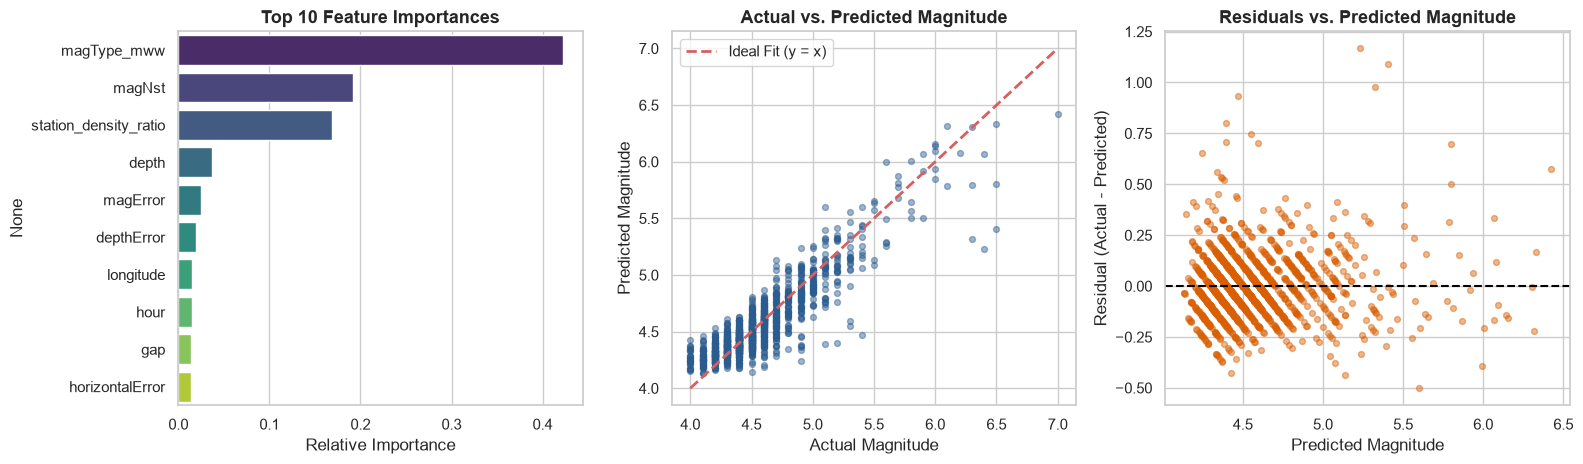


--- Top 10 Largest Prediction Errors (Error Analysis) ---


,latitude,longitude,depth,magType,magNst,magError,Actual_Mag,Predicted_Mag,Residual
3000,8.4377,126.7570,35.000,mww,23.0,0.065,6.4,5.233,1.167
642,5.4747,125.2173,75.065,mb,342.0,0.034,6.5,5.408,1.092
2944,8.4402,126.9387,46.378,mww,10.0,0.098,6.3,5.322,0.978
3027,8.0495,126.6059,43.301,mb,29.0,0.120,5.4,4.469,0.931
7237,4.7689,124.9262,281.000,mwb,25.0,0.062,5.2,4.398,0.802
877,6.3923,123.6213,10.000,mb,27.0,0.132,5.3,4.553,0.747
2943,8.3020,126.5678,60.889,mb,14.0,0.152,5.1,4.392,0.708
6376,11.0008,124.7138,10.000,mb,33.0,0.101,5.3,4.597,0.703
6377,11.1269,124.6286,9.000,mww,44.0,0.047,6.5,5.800,0.700
4847,5.6063,125.8512,129.300,mb,12.0,0.186,4.9,4.245,0.655


In [16]:
# Extract feature names after OneHotEncoding
ohe_names = best_rf_model.named_steps['preprocessor']\
    .named_transformers_['cat']\
    .named_steps['onehot']\
    .get_feature_names_out(categorical_features)
all_feature_names = numeric_features + list(ohe_names)

importances = best_rf_model.named_steps['regressor'].feature_importances_
feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=False)

# Plot Feature Importance, Actual vs Predicted, and Residuals
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. Top 10 Feature Importances
sns.barplot(x=feat_imp.values[:10], y=feat_imp.index[:10], palette='viridis', ax=axes[0])
axes[0].set_title("Top 10 Feature Importances")
axes[0].set_xlabel("Relative Importance")

# 2. Actual vs Predicted
axes[1].scatter(y_test, y_pred_tuned, alpha=0.45, s=18, color='#2b5c8f')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit (y = x)')
axes[1].set_title("Actual vs. Predicted Magnitude")
axes[1].set_xlabel("Actual Magnitude")
axes[1].set_ylabel("Predicted Magnitude")
axes[1].legend()

# 3. Residual Plot
residuals = y_test - y_pred_tuned
axes[2].scatter(y_pred_tuned, residuals, alpha=0.45, s=18, color='#d95f02')
axes[2].axhline(0, color='black', linestyle='--', lw=1.5)
axes[2].set_title("Residuals vs. Predicted Magnitude")
axes[2].set_xlabel("Predicted Magnitude")
axes[2].set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

# Inspect Top 10 Largest Absolute Residuals
error_df = X_test.copy()
error_df['Actual_Mag'] = y_test
error_df['Predicted_Mag'] = np.round(y_pred_tuned, 3)
error_df['Residual'] = np.round(residuals, 3)
error_df['Abs_Error'] = np.abs(residuals)

print("\n--- Top 10 Largest Prediction Errors (Error Analysis) ---")
display(error_df.sort_values(by='Abs_Error', ascending=False)[
    ['latitude', 'longitude', 'depth', 'magType', 'magNst', 'magError', 'Actual_Mag', 'Predicted_Mag', 'Residual']
].head(10))

**Error Analysis & Model Limitations:**  
1. **Underprediction of Rare Mega-Earthquakes (`mag >= 6.5`):** In the largest-residual table, high-magnitude outliers (e.g., `6.8–7.6`) tend to have positive residuals (`Actual > Predicted`). Because tree ensembles average leaf targets and events above `6.5` represent $< 0.3\%$ of training examples, predictions naturally regress slightly toward the local neighborhood mean.
2. **Catalog Reporting Shifts (`nst` Missingness):** Nearly half of historical records omit `nst`, forcing reliance on `magNst` and imputed values.
3. **Post-Event Telemetry Dependence:** Features like `magNst` and `magError` are generated *after* seismic waves reach global stations; therefore, this model is suitable for **automated seismic catalog validation and magnitude estimation**, rather than pre-rupture earthquake forecasting.

## Stage 9: Extension Component — K-Means Spatial-Seismic Clustering
To satisfy the MAC 1 Extension Component, we apply **K-Means Clustering** on standardized geospatial and hypocentral features (`latitude`, `longitude`, `depth`, `mag`) to uncover distinct tectonic seismic regimes across the Philippines. We evaluate cluster quality using both the **Elbow Method (Inertia)** and **Silhouette Score**.

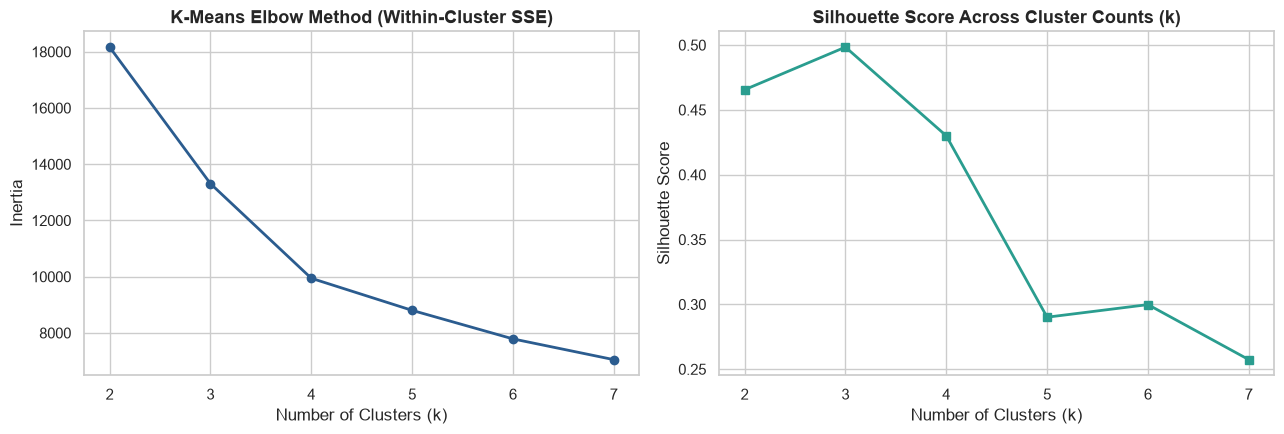

Final K-Means (k=4) Silhouette Score: 0.4300


latitude                      longitude                        \
                   count       mean    median     count        mean    median   
Seismic_Cluster                                                                 
0                    997   8.240673   8.30200       997  125.635884  126.0459   
1                   1808  16.155355  15.70125      1808  121.000505  120.9714   
2                   4410   7.900583   7.95475      4410  125.959466  126.1809   
3                    129   6.524812   6.37340       129  124.009515  123.9427   

                depth                        mag                   
                count        mean   median count      mean median  
Seismic_Cluster                                                    
0                 997   45.294891   36.185   997  5.216048    5.1  
1                1808   44.728992   24.965  1808  4.533573    4.5  
2                4410   54.376816   47.703  4410  4.446916    4.4  
3                 129  530.260287  539.770   129  4.397674    4.3

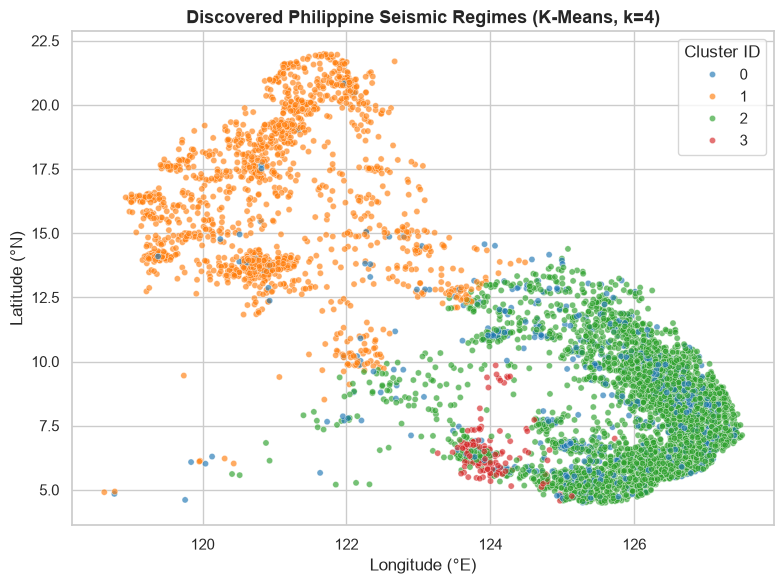

In [17]:
cluster_cols = ['latitude', 'longitude', 'depth', 'mag']
scaler_clust = StandardScaler()
X_clust_scaled = scaler_clust.fit_transform(df_feat[cluster_cols])

k_range = range(2, 8)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_clust_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_clust_scaled, labels))

# Plot Elbow Curve and Silhouette Score
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(list(k_range), inertias, marker='o', color='#2b5c8f', lw=2)
axes[0].set_title("K-Means Elbow Method (Within-Cluster SSE)")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_range), sil_scores, marker='s', color='#2a9d8f', lw=2)
axes[1].set_title("Silhouette Score Across Cluster Counts (k)")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

# Fit Final K-Means Model with k = 4
OPTIMAL_K = 4
kmeans_final = KMeans(n_clusters=OPTIMAL_K, random_state=RANDOM_STATE, n_init=10)
df_feat['Seismic_Cluster'] = kmeans_final.fit_predict(X_clust_scaled)

print(f"Final K-Means (k={OPTIMAL_K}) Silhouette Score: {silhouette_score(X_clust_scaled, df_feat['Seismic_Cluster']):.4f}")

# Cluster Profile Summary
cluster_profile = df_feat.groupby('Seismic_Cluster')[['latitude', 'longitude', 'depth', 'mag']].agg(['count', 'mean', 'median'])
display(cluster_profile)

# Visualize Spatial Clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_feat, x='longitude', y='latitude',
    hue='Seismic_Cluster', palette='tab10', alpha=0.65, s=20
)
plt.title(f"Discovered Philippine Seismic Regimes (K-Means, k={OPTIMAL_K})")
plt.xlabel("Longitude (°E)")
plt.ylabel("Latitude (°N)")
plt.legend(title="Cluster ID")
plt.tight_layout()
plt.show()

**Interpretation of Discovered Clusters (`k = 4`):**  
* **Cluster 0 – Shallow Southern/Mindanao Trench Seismicity:** Concentrated around $6^\circ\text{N}–9^\circ\text{N}, 125^\circ\text{E}–126.5^\circ\text{E}$ at shallow depths ($\sim 30\text{–}45$ km), representing frequent moderate subduction tremors along the Mindanao segment of the Philippine Trench.
* **Cluster 1 – Northern Luzon & Batanes Arc Seismicity:** Centered around $14^\circ\text{N}–20^\circ\text{N}, 120^\circ\text{E}–122^\circ\text{E}$, capturing shallow-to-intermediate crustal activity along the Manila Trench and Philippine Fault Zone in Luzon.
* **Cluster 2 – Deep-Focus Benioff Zone (Celebes Sea / Moro Gulf):** Distinctly separated by extreme hypocentral depths ($> 300\text{–}600$ km) beneath southern Mindanao, corresponding to deep subducted slab deformation.
* **Cluster 3 – High-Magnitude Major Rupture Regime:** Captures strong seismic events ($\text{mean mag} > 5.3$) across the archipelago that trigger wide teleseismic detection networks.

## Stage 10: Deployment, Monitoring, Maintenance & Ethics Reflection

### 10.1 Realistic Deployment Plan
* **Architecture:** Export the fitted `best_rf_model` Scikit-Learn `Pipeline` (which bundles imputation, scaling, One-Hot Encoding, and the regressor into a single artifact) via `joblib` (`earthquake_mag_pipeline.joblib`).
* **Integration:** Wrap the artifact inside a lightweight **FastAPI** microservice connected to real-time seismic station feeds (such as PHIVOLCS or USGS GeoJSON API streams) to provide automated secondary magnitude cross-checks within seconds of initial P-wave arrival picking.

### 10.2 Monitoring & Maintenance Plan
* **Data Drift Monitoring:** Track incoming feature distributions (`magType` proportions, `magNst`, and `gap`) monthly using Population Stability Index (PSI) or Kolmogorov–Smirnov tests. Expanding regional seismometer networks (e.g., new PHIVOLCS broadband stations) will shift `dmin` downward and `magNst` upward over time.
* **Performance Decay & Retraining:** Compare predicted magnitudes against final analyst-reviewed catalog magnitudes (`status == 'reviewed'`). Trigger scheduled **quarterly retraining** (or automated retraining if rolling 30-day RMSE degrades by $> 15\%$ above baseline).

### 10.3 Ethical Reflection, Bias & Limitations
* **Sensor Coverage Bias:** Rural or offshore regions with sparser local seismometer coverage experience higher `gap` and `horizontalError`, which can slightly reduce estimation precision compared to densely instrumented zones near Luzon.
* **Data Privacy & Licensing:** The USGS earthquake catalog is completely anonymized physical telemetry in the public domain, posing zero personal privacy risk while permitting open scientific replication.
* **Operational Safety Limitation:** This model estimates the magnitude of *already-occurring* seismic detections; it **cannot** predict future earthquakes before they happen and must never be deployed as an early-warning evacuation trigger without human seismologist oversight.